# 04 — Machine-learning models

**Question:** does GPS ground deformation improve weekly forecasts beyond what past seismicity already gives?

Phase 5 (`03_baselines`) found that the paper's uplift-driven model tracks the long-term level of seismicity, while a 4-week rolling mean follows swarms. Here we combine both kinds of information in one model and, crucially, compare the **same model with and without GPS features** (an ablation): the difference is what GPS adds.

**Plan:**
1. Features, and a check that none of them uses future data. *(this step)*
2. Poisson regression (GLM), with and without GPS.
3. LightGBM (gradient-boosted trees), with and without GPS.
4. P(M ≥ 3 next week): from the count models, and as direct classifiers.
5. SHAP explanations of the best model.

Same evaluation as phase 5: test weeks January 2020 – December 2025 (312 weeks, plus 2023–2025 separately), walk-forward with expanding window. Training starts in 2013 (before that, uplift is mostly GPS noise and nearly every week is empty). **The bar:** Poisson deviance 14.8 (2020–2025) / 24.1 (2023–2025), Brier 0.107, log-loss 0.335.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.features import (ALL_FEATURES, COMBINED_FEATURES, GPS_FEATURES, SEISMIC_FEATURES,
                          build_features, check_no_lookahead, station_scales)

events = pd.read_parquet("../data/processed/catalogue.parquet")
gps = pd.read_parquet("../data/processed/gps_daily.parquet")
table = build_features(events, gps, start="2005-01-03", end="2025-12-28")
TRAIN_START, TEST_START, TEST_END = "2013-01-07", "2020-01-06", "2025-12-22"
print(f"{len(table)} weeks, {len(ALL_FEATURES)} features")

1095 weeks, 19 features


## 1. Features

All features for the week starting on Monday *w* use data up to the Sunday before (`src/features.py`):

| Group | Feature | Meaning |
|---|---|---|
| Seismicity | `log_count_1w` | log(1 + events with M ≥ 0.6 last week) |
| | `log_mean_2w`, `log_mean_4w`, `log_mean_12w` | log(1 + mean weekly count over the last 2, 4, 12 weeks) |
| | `log_max_4w` | log(1 + largest weekly count in the last 4 weeks): catches swarms |
| | `log_count_m2_4w`, `log_count_m25_4w` | log(1 + events with M ≥ 2, M ≥ 2.5 in the last 4 weeks) |
| | `weeks_since_large` | weeks since the last week with an M ≥ 3 (capped at 260) |
| | `log_N` | log(1 + cumulative count since 2005) |
| GPS | `delta_rite` | RITE uplift since Jan 2005 (cm), 7-day mean |
| | `rate_rite_7d` … `rate_rite_90d` | RITE uplift rate over the last 7, 14, 28, 90 days (cm/year) |
| | `accel_rite` | change of the 28-day rate over 4 weeks |
| | `rate_near_28d` | shared 28-day rate of the 7 near stations (RITE, SOLO, PIS1, STRZ, ARFE, IPPO, ASTR), in RITE units |
| | `rate_far_28d` | mean 28-day rate of 4 far stations (LICO, FRUL, NAMM, MAFE): mostly common noise |
| Combined | `log_N_x_uplift` | log(1 + N × uplift per week): the paper's "rate ∝ N × uplift rate" |
| | `log_paper_mu` | log(1 + the paper's weekly forecast μ, from `03_baselines` section 4) |

**The near-station rate.** Station *i* moves about *sᵢ* times as much as RITE (one source, one shape). Its rate is then about *sᵢ·S*, where *S* is the shared rate. The least-squares estimate from the stations reporting that day is S = Σ sᵢ·rateᵢ / Σ sᵢ². Stations that move little get little weight, so their noise isn't amplified. The scales *sᵢ* are fixed constants, estimated from 2017–2019 (before the test period):

In [2]:
station_scales(gps).round(3).to_frame().T

,RITE,SOLO,PIS1,STRZ,ARFE,IPPO,ASTR
scale,1.0,0.69,0.559,0.571,0.442,0.159,0.231


**Checking for look-ahead.** The most common way to fool yourself in forecasting is a feature that accidentally uses the week being forecast (or later). `check_no_lookahead` deletes all events and GPS data from week *w* onwards, rebuilds the features, and compares week *w*'s row with the full-data version. Any feature that peeks would change.

In [3]:
check_weeks = ["2013-01-07", "2016-06-06", "2020-01-06", "2023-09-25", "2024-05-20", "2025-02-17", "2025-12-22"]
check_no_lookahead(events, gps, "2005-01-03", "2025-12-28", check_weeks, full=table)

,max_abs_difference,features_compared
2013-01-07,0.0,19.0
2016-06-06,0.0,19.0
2020-01-06,0.0,19.0
2023-09-25,0.0,19.0
2024-05-20,0.0,19.0
2025-02-17,0.0,19.0
2025-12-22,0.0,19.0


Every feature is identical: none uses data from its own week or later. (19 of the 19 features are compared; the station scales are the fixed 2017–2019 constants in both cases.)

To show that the check would catch a mistake, here is a deliberately *leaky* feature, the week's own event count, computed both ways:

In [4]:
from src.series import event_counts

def leaky_feature(evts, week):
    """WRONG on purpose: log(1 + this week's own count)."""
    counts = event_counts(evts, "W", mc=0.6, start="2005-01-03", end="2025-12-28")
    return np.log1p(counts.get(pd.Timestamp(week, tz="UTC"), 0))

for week in ["2024-05-20", "2025-02-17"]:
    cut = pd.Timestamp(week, tz="UTC")
    print(f"{week}: full data {leaky_feature(events, week):.2f}, "
          f"data cut at the week {leaky_feature(events[events['time'] < cut], week):.2f}  -> caught")

2024-05-20: full data 5.08, data cut at the week 0.00  -> caught
2025-02-17: full data 5.81, data cut at the week 0.00  -> caught


**How do the features relate to next week's count?** Rank (Spearman) correlation of each feature with log(1 + count) over the training-and-test span 2013–2025. This is only a first look: correlations include the shared upward trend, and models will combine features.

In [5]:
span = table.loc[TRAIN_START:TEST_END]
target = np.log1p(span["count"])
corr = span[ALL_FEATURES].corrwith(target, method="spearman").rename("spearman_with_log_count")
group = pd.Series({f: g for g, fs in [("seismicity", SEISMIC_FEATURES), ("GPS", GPS_FEATURES),
                                      ("combined", COMBINED_FEATURES)] for f in fs}, name="group")
pd.concat([group, corr.round(2)], axis=1).sort_values("spearman_with_log_count", ascending=False)

,group,spearman_with_log_count
delta_rite,GPS,0.79
log_N,seismicity,0.78
log_mean_4w,seismicity,0.77
log_mean_12w,seismicity,0.76
log_max_4w,seismicity,0.75
log_mean_2w,seismicity,0.75
log_N_x_uplift,combined,0.74
log_count_1w,seismicity,0.73
log_paper_mu,combined,0.73
rate_rite_90d,GPS,0.70


In [6]:
# How similar are the GPS features to each other? (Spearman, 2013-2025)
span[GPS_FEATURES].corr(method="spearman").round(2)

,delta_rite,rate_rite_7d,rate_rite_14d,rate_rite_28d,rate_rite_90d,accel_rite,rate_near_28d,rate_far_28d
delta_rite,1.00,0.18,0.37,0.59,0.76,0.03,0.52,0.03
rate_rite_7d,0.18,1.00,0.41,0.22,0.16,0.12,0.23,0.12
rate_rite_14d,0.37,0.41,1.00,0.58,0.39,0.32,0.57,0.28
rate_rite_28d,0.59,0.22,0.58,1.00,0.69,0.51,0.97,0.46
rate_rite_90d,0.76,0.16,0.39,0.69,1.00,-0.07,0.61,0.01
accel_rite,0.03,0.12,0.32,0.51,-0.07,1.00,0.56,0.54
rate_near_28d,0.52,0.23,0.57,0.97,0.61,0.56,1.00,0.59
rate_far_28d,0.03,0.12,0.28,0.46,0.01,0.54,0.59,1.00


**What the features show:**

- **No look-ahead:** all 19 features are identical when every bit of data from the forecast week onwards is deleted, at 7 weeks from 2013 to the last test week; the deliberately leaky feature is caught at once.
- **Slow features correlate most** with next week's count: uplift level (`delta_rite`, 0.79), cumulative count (`log_N`, 0.78), and recent mean counts (0.73–0.77). Much of this is the shared upward trend from 2013 to 2025, so these numbers don't say what helps *week to week*.
- **Short-window uplift rates carry less:** 0.56 for the 28-day rate, 0.36 for 14 days, 0.20 for 7 days. Shorter windows are noisier.
- **Some GPS features are mostly noise or duplicates:**
  - The near-station rate is almost the same as RITE's 28-day rate (correlation 0.97), so averaging stations adds little beyond RITE (as phase 4 suggested).
  - The far-station rate correlates 0.46 with RITE's 28-day rate although the far stations barely move: that's GPS noise common to the whole network (for example seasonal or processing effects). And the acceleration correlates 0.54 with the far-station rate, so it is largely that common noise too.
  - This suggests a cleaner signal for later: RITE's rate *minus* the far-station rate. We'll see first whether the models find the GPS features useful as they are.
- `weeks_since_large` correlates −0.74: long gaps since the last M ≥ 3 mean quiet periods (and the early years, when there were none at all).

## 2. Poisson regression (GLM), with and without GPS

A Poisson GLM models log(expected count) as a weighted sum of the features: the same kind of model as the paper's rate equation, but with many inputs. An **L2 penalty** shrinks the weights towards zero to avoid overfitting the ~360–700 training weeks: the stronger the penalty, the closer the weights stay to zero.

**How each forecast is made** (`src/models.py`), with the first test week of 2023 (Monday 2 January) as the example:

1. **Training data:** every week from 7 January 2013 up to the last complete week before the forecast (the week starting 26 December 2022). Each row is one *week*: its count of events with M ≥ 0.6 is the target, its features are the inputs. Weeks with a missing feature (a few GPS gaps) are dropped.
2. **Standardise:** each feature's mean and standard deviation are computed on these training weeks only, and the features are rescaled to mean 0 and standard deviation 1. This makes the weights comparable, and the scaling uses only the past.
3. **Fit** the weights by maximising the Poisson likelihood, with the penalty chosen for 2023 (below).
4. **Predict:** standardise the 2 January week's features with the same means and standard deviations and compute the expected count. A missing feature in the forecast week takes the training median.

For the next week (9 January 2023) everything is repeated from scratch with one more training week, and so on: the weights are refitted before every test week.

**How the penalty is chosen:** once a year, at the first test week of that year, never using test weeks, by a **grid search over time-ordered folds** (scikit-learn's `GridSearchCV` with `TimeSeriesSplit`; `tune` in `src/models.py`). For 2023, the training weeks available then (2013 to 26 December 2022) are split into three folds, each validating on one year with a model trained only on the years before it:

| Fold | Trained on | Validated on |
|---|---|---|
| 1 | 2013 – 2019 | 2020 |
| 2 | 2013 – 2020 | 2021 |
| 3 | 2013 – 2021 | 2022 |

For each candidate penalty (0.001, 0.01, 0.1, 0.3, 1, 3, 10, 30), a model is fitted in each fold and scored on its validation year by Poisson deviance (our own function, with the same 0.1 floor as the test scores). The penalty with the lowest **mean over the three folds** is used for every forecast in 2023. So the penalty is chosen by asking: *which penalty would have made the best forecasts in each of the last three years, with models trained only on earlier data?* Averaging three years makes the choice less sensitive to a single swarm than one validation year would be.

Two points to be careful about:

- **Folds must be time-ordered.** `GridSearchCV`'s default (k-fold) would mix past and future, training on 2022 to "predict" 2020, which is exactly the leakage the whole evaluation avoids. `TimeSeriesSplit` only ever validates on weeks after the training weeks.
- **Simplification:** within each fold the model is fitted once and then predicts its whole validation year, rather than being refitted week by week as in the real test. It only needs to rank the candidates, but tuning scores aren't directly comparable with test scores.

In one line: **every forecast in 2023 uses weights trained on all weeks from 2013 up to the week before it, with a penalty chosen by how well models trained on earlier data forecast 2020, 2021 and 2022.** LightGBM (section 3) follows the same scheme, tuning tree settings instead of the penalty.

Three feature sets:

- **seismic:** past seismicity only (9 features);
- **seismic + GPS:** adds the 8 GPS features;
- **all:** adds the 2 combined features too (N × uplift, the paper's μ).

**Is a difference real?** Scores are averages over 312 weeks, and a few swarm weeks dominate them. So for pairs of models we compute the per-week difference in deviance and a 95% interval by a *block bootstrap*: resample blocks of 8 consecutive weeks (swarms span several weeks) 2,000 times. If the interval contains 0, we can't tell the two models apart.

In [7]:
import warnings

from src.baselines import make_rolling_mean, persistence
from src.evaluation import (count_scores, paired_difference, walk_forward, weekly_poisson_deviance)
from src.models import GLM_ALPHAS, _training_rows, glm_coefficients, make_glm_forecaster

warnings.filterwarnings("ignore", category=RuntimeWarning)
test = table.loc[TEST_START:TEST_END]
recent = test.index >= "2023-01-01"
feature_sets = {"glm_seismic": SEISMIC_FEATURES,
                "glm_seismic_gps": SEISMIC_FEATURES + GPS_FEATURES,
                "glm_all": ALL_FEATURES}

count_forecasts = {"persistence": walk_forward(table, persistence, TEST_START, TEST_END),
                   "rolling_mean_4w": walk_forward(table, make_rolling_mean(4), TEST_START, TEST_END)}
glm_forecasters = {}
for name, features in feature_sets.items():
    glm_forecasters[name] = make_glm_forecaster(features, name)
    count_forecasts[name] = walk_forward(table, glm_forecasters[name], TEST_START, TEST_END)

pd.concat({
    "2020–2025": count_scores(test["count"], count_forecasts),
    "2023–2025": count_scores(test["count"][recent], {n: f[recent] for n, f in count_forecasts.items()}),
}, axis=1).round(2)

2020–2025               2023–2025       
                poisson_deviance    mae poisson_deviance    mae
persistence                15.99  12.16            24.11  20.70
rolling_mean_4w            14.81  12.07            25.35  21.26
glm_seismic                13.39  11.45            22.46  20.06
glm_seismic_gps            13.60  11.49            23.04  20.19
glm_all                    13.66  11.67            23.11  20.55

In [8]:
# Penalty chosen each year (larger = stronger shrinkage); grid: GLM_ALPHAS.
pd.DataFrame({name: f.chosen for name, f in glm_forecasters.items()})

,glm_seismic,glm_seismic_gps,glm_all
2020,1.0,3.0,3.0
2021,3.0,3.0,3.0
2022,3.0,3.0,3.0
2023,1.0,3.0,3.0
2024,1.0,3.0,3.0
2025,1.0,3.0,3.0


In [9]:
# The grid search behind the 2023 choice for the full model: Poisson deviance of each
# candidate penalty in each validation year (fold 1 = 2020, 2 = 2021, 3 = 2022), and the mean.
from src.models import tuning_table

tuning_table(glm_forecasters["glm_all"].tuning[2023], "poissonregressor__alpha").round(2)

,fold 1,fold 2,fold 3,mean
alpha,,,,
0.001,11.51,16.85,5.83,11.40
0.010,10.99,7.11,5.64,7.91
0.100,8.73,5.36,5.23,6.44
0.300,6.95,4.55,5.07,5.52
1.000,5.65,3.63,4.92,4.73
3.000,5.41,3.15,5.18,4.58
10.000,6.13,3.45,6.69,5.42
30.000,7.09,4.47,9.39,6.98


In [10]:
per_week = {name: weekly_poisson_deviance(test["count"], f) for name, f in count_forecasts.items()}
pairs = [("glm_all", "glm_seismic", "GPS + combined added to seismic"),
         ("glm_seismic_gps", "glm_seismic", "GPS added to seismic"),
         ("glm_seismic", "rolling_mean_4w", "seismic GLM against best baseline"),
         ("glm_all", "rolling_mean_4w", "full GLM against best baseline")]
pd.DataFrame({label: paired_difference(per_week[a], per_week[b]) for a, b, label in pairs}).T.round(2)

,mean_difference,ci_low,ci_high
GPS + combined added to seismic,0.27,-0.53,1.06
GPS added to seismic,0.21,-0.58,0.98
seismic GLM against best baseline,-1.42,-3.77,0.34
full GLM against best baseline,-1.15,-3.86,0.88


**What the full model learned.** Coefficients of the GLM with all features, fitted on 2013–2025 with the penalty chosen for 2025. Each coefficient is per standard deviation of its feature: +0.3 means one standard deviation more multiplies the expected count by e^0.3 ≈ 1.35, other features fixed. Correlated features share their weight, so individual values should be read with care.

In [11]:
final_train = _training_rows(table.loc[:TEST_END], ALL_FEATURES)
coefs = glm_coefficients(final_train, ALL_FEATURES, glm_forecasters["glm_all"].chosen[2025])
group = pd.Series({f: g for g, fs in [("seismicity", SEISMIC_FEATURES), ("GPS", GPS_FEATURES),
                                      ("combined", COMBINED_FEATURES)] for f in fs}, name="group")
pd.concat([group, coefs.round(3)], axis=1).sort_values("coefficient", key=abs, ascending=False)

,group,coefficient
log_count_1w,seismicity,0.286
log_mean_2w,seismicity,0.193
delta_rite,GPS,0.159
log_N,seismicity,0.149
weeks_since_large,seismicity,-0.143
log_mean_4w,seismicity,0.132
rate_rite_7d,GPS,0.115
log_max_4w,seismicity,0.112
log_paper_mu,combined,0.081
log_N_x_uplift,combined,0.076


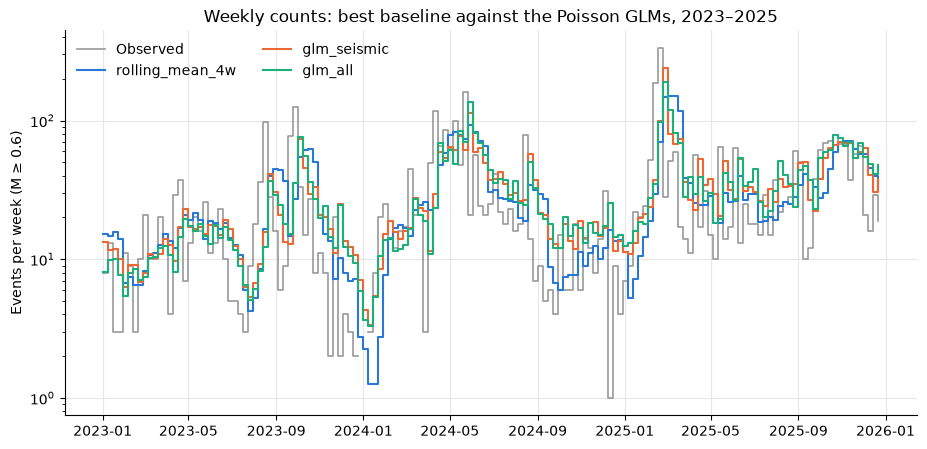

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
shown = test.loc["2023-01-01":]
ax.plot(shown.index, shown["count"].where(shown["count"] > 0), drawstyle="steps-post", color="0.6",
        linewidth=1.2, label="Observed")
for name, colour in [("rolling_mean_4w", "#2a78d6"), ("glm_seismic", "#eb6834"), ("glm_all", "#1baf7a")]:
    f = count_forecasts[name].loc["2023-01-01":]
    ax.plot(f.index, f, drawstyle="steps-post", linewidth=1.5, color=colour, label=name)
ax.set_yscale("log")
ax.set_ylabel("Events per week (M ≥ 0.6)")
ax.set_title("Weekly counts: best baseline against the Poisson GLMs, 2023–2025")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.show()

**What the GLMs show:**

- **The GLM beats the bar, on seismicity alone.** With past seismicity only, its Poisson deviance is 13.4 (2020–2025) and 22.5 (2023–2025), against the best baselines' 14.8 and 24.1; its MAE is also lower (11.5 against 12.1). It reacts more strongly to last week's count than the 4-week mean (largest coefficient), so it follows a swarm sooner, but it also leans on the longer-term level.
- **But the gain is uncertain:** the block-bootstrap interval for the seismic GLM against the 4-week mean is −3.8 to +0.3 per week. It includes 0, so with these 312 weeks we can't be confident it is really better.
- **Adding GPS doesn't help:** with GPS features the deviance is 13.6, with GPS and combined features 13.7, slightly *worse* than seismicity alone; the differences (+0.21 and +0.27 per week, intervals about −0.6 to +1.0) are indistinguishable from zero. The penalty chosen with GPS is also stronger (3 every year, against mostly 1 for seismicity alone), a sign that the extra features mostly add noise to fit.
- **The tuning is more stable over three validation years.** An earlier version validated on the last year only; its choices jumped between 0.1 and 3 and its scores were almost the same (seismic GLM 13.3). For 2023, the table above shows why averaging helps: 2022 alone would pick a penalty of 1, the 2021 fold prefers 3, and the mean settles on 3. Very weak penalties (0.001, 0.01) do badly in every fold: without shrinkage the model overfits.
- **The fitted weights tell the same story.** The largest are on recent counts (last week 0.29, last 2 weeks 0.19). Among GPS features, the uplift level (`delta_rite`, 0.16) mostly duplicates the long-term trend already in `log_N`, and the 7-day uplift rate gets a small weight (0.12). The paper-inspired combined features get 0.08 each.

**So far, the answer to the research question for linear models:** once recent seismicity is known, GPS uplift adds no measurable skill to next week's count. Next: LightGBM, which can capture interactions (for example, uplift mattering only during swarms) that a linear model can't.

## 3. LightGBM, with and without GPS

LightGBM builds an ensemble of small decision trees, each correcting the errors of the previous ones (gradient boosting). With a **Poisson objective** it models log(expected count), like the GLM, but as a sum of tree outputs instead of a weighted sum of features. So it can capture **non-linear effects** (a feature that only matters above some value) and **interactions** (for example uplift mattering only during a swarm), which a GLM can't.

Same training scheme as the GLM: refitted before every test week on all weeks from 2013; settings re-tuned once a year by grid search over the three previous years. Differences:

- No standardisation (trees only use the order of values) and no filling of missing values (LightGBM sends a missing value down whichever branch fitted best in training), so weeks with GPS gaps are kept.
- The grid (`LGBM_GRID`, 36 combinations): number of trees (50, 100, 300), leaves per tree (2, 4, 8; 2 leaves means one split per tree, so no interactions), the fewest training weeks per leaf (10, 30), and an L2 penalty on leaf values (0, 5). Learning rate 0.05, seed fixed. A first grid with larger trees (4–15 leaves, 100–300 trees) was tuned to its smallest values almost every year, so it was extended downwards.

In [13]:
from src.models import LGBM_GRID, make_lgbm_forecaster

lgbm_forecasters = {}
for name, features in {"lgbm_seismic": SEISMIC_FEATURES, "lgbm_seismic_gps": SEISMIC_FEATURES + GPS_FEATURES,
                       "lgbm_all": ALL_FEATURES}.items():
    lgbm_forecasters[name] = make_lgbm_forecaster(features, name)
    count_forecasts[name] = walk_forward(table, lgbm_forecasters[name], TEST_START, TEST_END)

shown_models = ["persistence", "rolling_mean_4w", "glm_seismic", "glm_all", "lgbm_seismic", "lgbm_seismic_gps", "lgbm_all"]
pd.concat({
    "2020–2025": count_scores(test["count"], {n: count_forecasts[n] for n in shown_models}),
    "2023–2025": count_scores(test["count"][recent], {n: count_forecasts[n][recent] for n in shown_models}),
}, axis=1).round(2)

2020–2025               2023–2025       
                 poisson_deviance    mae poisson_deviance    mae
persistence                 15.99  12.16            24.11  20.70
rolling_mean_4w             14.81  12.07            25.35  21.26
glm_seismic                 13.39  11.45            22.46  20.06
glm_all                     13.66  11.67            23.11  20.55
lgbm_seismic                14.84  12.00            25.16  20.97
lgbm_seismic_gps            13.68  11.94            22.38  20.86
lgbm_all                    15.10  12.39            25.22  21.81

In [14]:
# Settings chosen each year: (number of trees, leaves per tree, fewest weeks per leaf, leaf penalty).
pd.DataFrame({name: {year: (p["n_estimators"], p["num_leaves"], p["min_child_samples"], p["reg_lambda"])
                     for year, p in f.chosen.items()} for name, f in lgbm_forecasters.items()})

,lgbm_seismic,lgbm_seismic_gps,lgbm_all
2020,"(100, 2, 10, 0.0)","(100, 2, 10, 0.0)","(100, 2, 10, 0.0)"
2021,"(300, 2, 10, 5.0)","(100, 8, 30, 0.0)","(100, 4, 10, 0.0)"
2022,"(100, 2, 10, 0.0)","(100, 2, 30, 5.0)","(100, 2, 30, 5.0)"
2023,"(100, 2, 10, 0.0)","(300, 2, 30, 0.0)","(300, 2, 30, 0.0)"
2024,"(300, 2, 10, 5.0)","(300, 2, 10, 5.0)","(300, 2, 10, 5.0)"
2025,"(100, 8, 30, 5.0)","(300, 2, 30, 5.0)","(100, 4, 30, 0.0)"


In [15]:
per_week = {name: weekly_poisson_deviance(test["count"], f) for name, f in count_forecasts.items()}
pairs = [("lgbm_all", "lgbm_seismic", "GPS + combined added to seismic (LightGBM)"),
         ("lgbm_seismic_gps", "lgbm_seismic", "GPS added to seismic (LightGBM)"),
         ("lgbm_seismic", "glm_seismic", "LightGBM against GLM (seismic)"),
         ("lgbm_seismic", "rolling_mean_4w", "LightGBM (seismic) against best baseline")]
pd.DataFrame({label: paired_difference(per_week[a], per_week[b]) for a, b, label in pairs}).T.round(2)

,mean_difference,ci_low,ci_high
GPS + combined added to seismic (LightGBM),0.26,-1.47,2.35
GPS added to seismic (LightGBM),-1.15,-3.80,1.07
LightGBM against GLM (seismic),1.44,0.17,3.01
LightGBM (seismic) against best baseline,0.03,-1.73,1.88


In [16]:
# Mean weekly forecast per year against the observed mean: does LightGBM fall behind the growth?
pd.DataFrame({"observed": test["count"], "glm_seismic": count_forecasts["glm_seismic"],
              "lgbm_seismic": count_forecasts["lgbm_seismic"]}).groupby(test.index.year).mean().round(1)

,observed,glm_seismic,lgbm_seismic
period_start,,,
2020,2.8,1.8,1.9
2021,3.2,2.4,3.7
2022,5.8,3.9,3.7
2023,17.7,17.0,13.3
2024,27.4,29.1,27.6
2025,42.9,45.4,42.7


**What LightGBM shows:**

- **It doesn't beat the GLM.** On seismicity alone its deviance is 14.8 (2020–2025), the same as the 4-week rolling mean and clearly worse than the GLM's 13.4: the interval for the gap (+0.2 to +3.0 per week) excludes zero, so this one is a real difference.
- **The data prefer the simplest trees.** The tuning nearly always picks trees with **2 leaves** (one split each), which means an additive model with no interactions at all, and often only 100 trees. A first grid with larger trees was tuned to its smallest values almost every year. The ~600 training weeks are too few and too noisy to learn interactions; and step-shaped trees fit a smooth multiplicative response less well than the GLM's log-linear one.
- **It falls behind the growth in 2023:** mean forecast 13.3 events/week against 17.7 observed (GLM: 17.0). That year the weekly count went above anything in the training data six times; a tree model can only partly forecast values it has never seen, while the GLM extrapolates its log-linear trend.
- **The GPS result is unstable.** Adding GPS features *lowered* LightGBM's deviance (14.8 → 13.7), but adding GPS *and* the two combined features *raised* it (15.1). The intervals (−3.8 to +1.1 and −1.5 to +2.4 per week) both include zero, and two closely related feature sets pointing in opposite directions is a sign of noise, not of a real effect: small changes in features change which settings the yearly tuning picks, and with 312 swarm-dominated weeks that moves the score by a point or more.

**So far, across both model families:** the best model is the GLM on seismicity alone (deviance 13.4 / 22.5), and no model shows a robust gain from GPS. Next: the M ≥ 3 target (step 4), where uplift might still matter for the probability of *larger* events even if not for counts.